# 03 - Model comparison

**Goal:** compare logistic regression, random forest, XGBoost and LightGBM on the validation year (2016), using the same time-based split, the same 12 features and the same metrics.

**Rules**
- Models are trained on 2003-2015 only and scored on 2016. The test year (2017) and the late-check years (2018-2019) are not touched.
- Each model handles class imbalance with its own weighting.
- At the fixed threshold of 0.5 the models are not directly comparable, because class weighting shifts their probabilities differently. The main comparison uses ROC-AUC and PR-AUC; thresholds are tuned in the next section.

import sys
sys.path.append("..")

import pandas as pd
from src.data.split import load_data, time_split, FEATURES, LABEL
from src.models.builders import all_models
from src.evaluation.metrics import evaluate

df = load_data()
train, validation, test, late = time_split(df)

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from src.data.split import load_data, time_split, FEATURES, LABEL
from src.models.builders import all_models
from src.evaluation.metrics import evaluate

df = load_data()
train, validation, test, late = time_split(df)

## 1. Train the four models and score them on validation

**Goal:** fit every model on the training period and record all metrics on 2016. The predicted probabilities are kept in `proba` for the threshold tuning that follows.

models = all_models(train[LABEL])

proba = {}
for name, model in models.items():
    model.fit(train[FEATURES], train[LABEL])
    proba[name] = model.predict_proba(validation[FEATURES])[:, 1]

results = pd.DataFrame({name: evaluate(validation[LABEL], p) for name, p in proba.items()})
results.round(3)

In [2]:
models = all_models(train[LABEL])

proba = {}
for name, model in models.items():
    model.fit(train[FEATURES], train[LABEL])
    proba[name] = model.predict_proba(validation[FEATURES])[:, 1]

results = pd.DataFrame({name: evaluate(validation[LABEL], p) for name, p in proba.items()})
results.round(3)

,logistic regression,random forest,xgboost,lightgbm
ROC-AUC,0.784,0.804,0.804,0.804
PR-AUC,0.601,0.633,0.631,0.630
precision,0.474,0.551,0.496,0.493
recall,0.772,0.697,0.792,0.793
F1,0.587,0.615,0.610,0.608
MCC,0.382,0.436,0.420,0.417
bug share,0.291,0.291,0.291,0.291


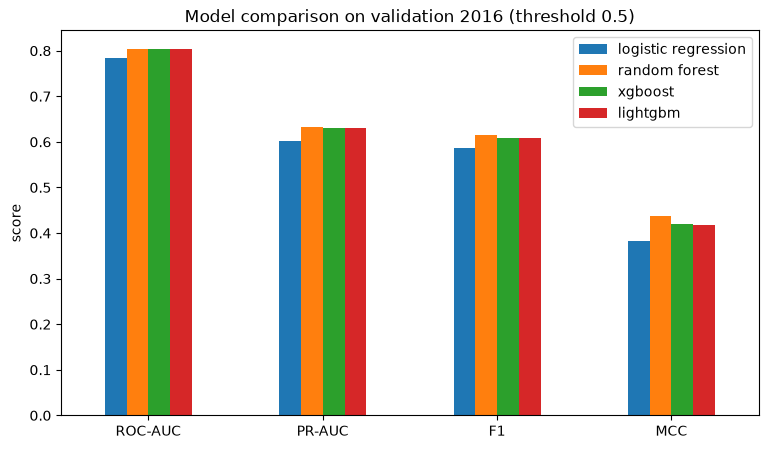

In [3]:
ax = results.loc[["ROC-AUC", "PR-AUC", "F1", "MCC"]].plot(kind="bar", figsize=(9, 5), rot=0, title="Model comparison on validation 2016 (threshold 0.5)")
ax.set_ylabel("score")
ax.figure.savefig("../reports/figures/03_model_comparison.png", dpi=150, bbox_inches="tight")
results.round(4).to_csv("../results/03_model_comparison_validation.csv")